# HAM10000 · v4 · Resampling + weights + a more stable training recipe

v3 (resampling + residual class weights) gave test macro-F1 0.745, but its validation curve jumped between 0.54 and 0.70 from epoch to epoch and train loss fell to 0.12 while validation loss stayed flat (overfitting). v4 keeps everything from v3 (lesion-safe splits, duplicate removal, per-epoch over/under-sampling, residual weights) and adds, **each behind its own switch** in the CONFIG cell:

| switch | what it does | why |
|---|---|---|
| `USE_SCHEDULE` | 1 warm-up epoch, then cosine learning-rate decay | v3 used a constant rate, so the curve was jumpy |
| `USE_EMA` | keeps a smoothed average of the weights and evaluates *that* | smoother curve, more reliable checkpoint |
| `LABEL_SMOOTH` | label smoothing 0.1 | less over-confident, less overfitting |
| `AUG_LEVEL="strong"` | random crop+zoom, stronger colour jitter, small random erasing | train loss was far below val loss |
| `PRELOAD` | decode and resize every image once into RAM | epochs become mostly GPU-bound instead of JPEG-decode-bound |
| `USE_TTA` | average predictions over 4 flips at the final evaluation | small, free gain |
| `POSTHOC` | tune one decision offset per class on the **validation** set, apply to test | v3's biggest errors (nv→mel) are a decision-threshold problem: AUC was already 0.966 |
| `BACKBONE`, `IMG_SIZE` | `resnet50` (default), `efficientnet_b3`, `convnext_tiny` (all CNNs); try `IMG_SIZE=300` | later experiments |

Nothing is guaranteed to help. The switches exist so you can turn each one off and see what it was worth. Only the validation set is used for any tuning; the test set is evaluated once at the end.

**How to use**
1. `DRY_RUN = True`, Run all. Checks the pipeline in a few minutes.
2. `DRY_RUN = False`, Run all with the defaults. Compare with v3 (macro-F1 0.7447).
3. If it looks good, change only `SEED` to 43 and 44 and Run all again. The last cells then show **mean ± std over seeds** and the **seed ensemble**.
4. Optional ablations: switch one feature off at a time (for example `POSTHOC = False`) and rerun.

**What every run saves:** the raw test numbers *and* the post-hoc-adjusted numbers, so you can always see how much post-hoc tuning added.

In [1]:
!nvidia-smi
from google.colab import drive
drive.mount('/content/drive')

Sat Oct 31 08:45:19 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   42C    P8             10W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [2]:
import os, json, time, random, glob, re, copy, math
import numpy as np
import pandas as pd

# ================= CONFIG: the only cell you edit between runs =================
BACKBONE     = "resnet50"      # "resnet50" | "efficientnet_b3" | "convnext_tiny"
WEIGHT_MODE  = "inverse"       # "none" | "inverse" | "sqrt" | "effective"  (computed from per-epoch counts if RESAMPLE)
DRY_RUN      = False            # True = tiny smoke run to check the pipeline. Set False for the real run.
SEED         = 42
EPOCHS       = 25
BATCH_SIZE   = 32
LR           = 2e-4
WEIGHT_DECAY = 1e-4
EFF_BETA     = 0.999           # only used by "effective"
IMG_SIZE     = 224             # 300 is worth trying later (slower)
COPY_LOCAL   = True            # copy images from Drive to Colab disk first

# ---- v4 training upgrades (each can be switched off to see what it adds) ----
USE_SCHEDULE  = True           # warm-up + cosine learning-rate decay
WARMUP_EPOCHS = 1
USE_EMA       = True           # evaluate a smoothed (moving-average) copy of the weights
EMA_DECAY     = 0.998
LABEL_SMOOTH  = 0.1            # 0 = off
AUG_LEVEL     = "strong"       # "base" (v3 augmentation) | "strong"
GRAD_CLIP     = 2.0
PRELOAD       = True           # decode + resize all images once into RAM (needs ~3 GB at 300px)
SELECT        = "best"         # "best" = epoch with best validation macro-F1 | "last" = final epoch
USE_TTA       = True           # average predictions over flips in the final evaluation
POSTHOC       = True           # tune per-class decision offsets on VALIDATION, apply to test
MEL_RECALL_FLOOR = None        # e.g. 0.70: post-hoc tuning may not push validation melanoma recall below this

# ---- resampling (TRAINING set only) ----
RESAMPLE            = True     # False = plain shuffle, weights from raw counts
TARGET_MODE         = "auto"   # "auto" (CAP_N / FLOOR_N / MAX_REPEAT) or "manual" (MANUAL_TARGETS)
CAP_N               = 1200     # class bigger than this  -> undersampled to this many images per epoch
FLOOR_N             = 500      # class smaller than this -> oversampled up to this many per epoch ...
MAX_REPEAT          = 6        # ... but an image is repeated at most this many times on average
MANUAL_TARGETS      = {"akiec": 500, "bcc": 500, "bkl": 880, "df": 500, "mel": 890, "nv": 1200, "vasc": 500}
RESAMPLE_EACH_EPOCH = True     # True = new random subset/repeats every epoch
LESION_AWARE        = True     # undersampling prefers images from lesions with few photos

# ---- near-duplicates (dHash, 256 bit). Only TRAIN images are ever removed. ----
DEDUP    = True
T_DUP    = 12                  # distance <= T_DUP  -> same picture (auto-removed from train)
T_REVIEW = 24                  # T_DUP < distance <= T_REVIEW -> reported only

DATA_DIR  = "/content/drive/MyDrive/HAM10000"                 # images + metadata (friend's shared folder)
SPLIT_DIR = DATA_DIR                                           # where train/val/test_split.csv live
OUT_DIR   = "/content/drive/MyDrive/HAM10000_model/imbalance_runs"
# ===============================================================================

assert WEIGHT_MODE in ("none", "inverse", "sqrt", "effective"), "bad WEIGHT_MODE"
assert TARGET_MODE in ("auto", "manual"), "bad TARGET_MODE"
assert BACKBONE in ("resnet50", "efficientnet_b3", "convnext_tiny"), "bad BACKBONE"
assert AUG_LEVEL in ("base", "strong") and SELECT in ("best", "last")
if DRY_RUN:
    EPOCHS = 2
    TARGET_MODE, CAP_N, FLOOR_N, MAX_REPEAT = "auto", 100, 50, 6     # scaled down to match the tiny dry-run subset
    print("*** DRY RUN: tiny subset, 2 epochs, scaled-down targets. Numbers are meaningless. Set DRY_RUN = False for the real run. ***")
RUN_LABEL = ("rs" if RESAMPLE else "norm") + "_" + WEIGHT_MODE
print(f"Run: {RUN_LABEL} | {BACKBONE} @ {IMG_SIZE}px | seed {SEED} | epochs {EPOCHS} | batch {BATCH_SIZE} | lr {LR}")
print(f"schedule {USE_SCHEDULE} | EMA {USE_EMA} | label smoothing {LABEL_SMOOTH} | aug {AUG_LEVEL} | preload {PRELOAD} | "
      f"select {SELECT} | TTA {USE_TTA} | post-hoc {POSTHOC}")
if RESAMPLE:
    print(f"Resampling: {TARGET_MODE} | cap {CAP_N} | floor {FLOOR_N} | max repeat {MAX_REPEAT} | "
          f"every epoch: {RESAMPLE_EACH_EPOCH} | lesion-aware: {LESION_AWARE} | dedup: {DEDUP} (T_DUP={T_DUP})")

Run: rs_inverse | resnet50 @ 224px | seed 42 | epochs 25 | batch 32 | lr 0.0002
schedule True | EMA True | label smoothing 0.1 | aug strong | preload True | select best | TTA True | post-hoc True
Resampling: auto | cap 1200 | floor 500 | max repeat 6 | every epoch: True | lesion-aware: True | dedup: True (T_DUP=12)


## 1 · Splits and leakage check
The check below compares **lesion ids**, not just image ids. If it fails, the notebook stops on purpose.

In [3]:
def check_no_leakage(train_df, val_df, test_df):
    pairs = [("train", "val", train_df, val_df), ("train", "test", train_df, test_df), ("val", "test", val_df, test_df)]
    rows = []
    for n1, n2, a, b in pairs:
        rows.append({"pair": f"{n1}-{n2}",
                     "shared_images": len(set(a["image_id"]) & set(b["image_id"])),
                     "shared_lesions": len(set(a["lesion_id"]) & set(b["lesion_id"]))})
    rep = pd.DataFrame(rows)
    print(rep.to_string(index=False))
    if (rep["shared_images"] > 0).any() or (rep["shared_lesions"] > 0).any():
        raise RuntimeError(
            "LEAKAGE: some lesions/images appear in more than one split, so test scores would be inflated. "
            "Do NOT trust results from these splits. Run the optional 'regroup' cell below to create "
            "lesion-grouped splits, point SPLIT_DIR at the new folder, and rerun (tell your team: the shared splits change).")
    print("OK: no image or lesion appears in more than one split.")
    return rep


def take_per_class(df, k, seed=0):
    # up to k rows per class (used only for the DRY_RUN smoke test); k may be an int or {class: int}
    d = df.sample(frac=1, random_state=seed)
    if isinstance(k, dict):
        return pd.concat([g.head(k.get(c, 0)) for c, g in d.groupby("dx")]).reset_index(drop=True)
    return d.groupby("dx").head(k).reset_index(drop=True)


def compute_class_weights(train_counts, mode, beta=0.999):
    n = np.asarray(train_counts, dtype=float)
    assert (n > 0).all(), "a class has zero training images"
    K, N = len(n), n.sum()
    if mode == "none":
        w = np.ones(K)
    elif mode == "inverse":              # w_c = N / (K * n_c)
        w = N / (K * n)
    elif mode == "sqrt":                 # w_c ~ 1/sqrt(n_c), rescaled to mean 1
        w = 1.0 / np.sqrt(n)
        w = w / w.mean()
    elif mode == "effective":            # Cui et al. 2019, normalised to sum K
        w = (1.0 - beta) / (1.0 - np.power(beta, n))
        w = w / w.sum() * K
    else:
        raise ValueError(mode)
    return w


def make_grouped_splits(metadata, out_dir, seed=42, n_splits=10):
    # ~80/10/10 split, stratified by class, grouped by lesion_id (a lesion never crosses splits)
    from sklearn.model_selection import StratifiedGroupKFold
    meta = metadata.reset_index(drop=True)
    sgkf = StratifiedGroupKFold(n_splits=n_splits, shuffle=True, random_state=seed)
    fold = np.full(len(meta), -1)
    for f, (_, idx) in enumerate(sgkf.split(meta, meta["dx"], groups=meta["lesion_id"])):
        fold[idx] = f
    test, val, train = meta[fold == 0], meta[fold == 1], meta[fold >= 2]
    check_no_leakage(train, val, test)
    os.makedirs(out_dir, exist_ok=True)
    train.to_csv(f"{out_dir}/train_split.csv", index=False)
    val.to_csv(f"{out_dir}/val_split.csv", index=False)
    test.to_csv(f"{out_dir}/test_split.csv", index=False)
    print("saved to", out_dir, "| sizes:", len(train), len(val), len(test))

In [4]:
metadata = pd.read_csv(f"{DATA_DIR}/HAM10000_metadata.csv")
train_df = pd.read_csv(f"{SPLIT_DIR}/train_split.csv")
val_df   = pd.read_csv(f"{SPLIT_DIR}/val_split.csv")
test_df  = pd.read_csv(f"{SPLIT_DIR}/test_split.csv")
print("Metadata:", metadata.shape, "| Train:", train_df.shape, "| Val:", val_df.shape, "| Test:", test_df.shape)

check_no_leakage(train_df, val_df, test_df)      # stops the notebook if there is leakage

if DRY_RUN:                                      # tiny stratified subset, only for the smoke test
    # unequal on purpose, so the dry run exercises BOTH undersampling (nv) and oversampling (df, vasc, akiec, bcc)
    train_df = take_per_class(train_df, dict(nv=150, mel=60, bkl=60, bcc=40, akiec=30, vasc=20, df=20), SEED)
    val_df   = take_per_class(val_df, 16, SEED)
    test_df  = take_per_class(test_df, 16, SEED)
    print("DRY RUN subset sizes:", len(train_df), len(val_df), len(test_df))

Metadata: (10015, 7) | Train: (7991, 7) | Val: (1008, 7) | Test: (1016, 7)
      pair  shared_images  shared_lesions
 train-val              0               0
train-test              0               0
  val-test              0               0
OK: no image or lesion appears in more than one split.


### Optional: only run this if the leakage check above failed
It builds new lesion-grouped 80/10/10 splits and saves them to your Drive. Afterwards set `SPLIT_DIR` in the CONFIG cell to the printed folder and rerun from the top. Your teammates must use the same new files, and the first baseline notebook's numbers are then invalid.

In [5]:
RUN_REGROUP = False     # set True ONLY if the leakage check failed
if RUN_REGROUP:
    make_grouped_splits(metadata, "/content/drive/MyDrive/HAM10000_model/splits_grouped", seed=SEED)

## 2 · Images, near-duplicates, per-epoch targets, class weights

In [6]:
from glob import glob as _glob

IMAGE_DIRS = [os.path.join(DATA_DIR, "HAM10000_images_part_1"), os.path.join(DATA_DIR, "HAM10000_images_part_2")]

if COPY_LOCAL and not DRY_RUN:
    LOCAL_IMG = "/content/ham_images"
    if not os.path.isdir(LOCAL_IMG) or len(os.listdir(LOCAL_IMG)) < 10015:
        os.makedirs(LOCAL_IMG, exist_ok=True)
        for d in IMAGE_DIRS:
            !cp -r "{d}/." {LOCAL_IMG}/
    IMAGE_DIRS = [LOCAL_IMG]

image_paths = {}
for image_dir in IMAGE_DIRS:
    for path in _glob(os.path.join(image_dir, "*.jpg")):
        image_paths[os.path.splitext(os.path.basename(path))[0]] = path
print("Total JPG images found:", len(image_paths))

classes = sorted(metadata["dx"].unique())                       # same alphabetical order as the first baseline
class_to_idx = {c: i for i, c in enumerate(classes)}
print("Classes:", class_to_idx)

for df in (train_df, val_df, test_df):
    df["image_path"] = df["image_id"].map(image_paths)
    df["label"] = df["dx"].map(class_to_idx)
for name, df in (("train", train_df), ("val", val_df), ("test", test_df)):
    assert df["image_path"].notna().all() and df["label"].notna().all(), f"{name}: missing image or label"
print("All images and labels found.")

Total JPG images found: 10015
Classes: {'akiec': 0, 'bcc': 1, 'bkl': 2, 'df': 3, 'mel': 4, 'nv': 5, 'vasc': 6}
All images and labels found.


### 2a · Near-duplicate check
HAM10000 has several photos per lesion and a few near-identical image pairs. This step hashes every image (dHash, 256 bit) and compares all pairs.
- **distance ≤ `T_DUP`:** same picture. A train image that is a near-copy of a val/test image is **dropped from train** (otherwise test scores are inflated). Of two near-identical train images, one is dropped.
- **`T_DUP` < distance ≤ `T_REVIEW`:** grey zone. Shown below as pictures for **you to judge**; nothing is removed automatically.
- Val and test sets are never changed. If val/test contain near-copies of each other, it is reported only.
- Hashes are cached on Drive, so later runs are fast.

In [7]:
from PIL import Image

# ======================= near-duplicate detection (dHash) =======================
def dhash_bits(path, size=16):
    """256-bit difference hash: grayscale, resize to (size+1) x size, compare horizontal neighbours."""
    im = Image.open(path)
    im.draft("L", (size * 8, size * 8))          # cheaper JPEG decode; hash stays consistent across runs
    a = np.asarray(im.convert("L").resize((size + 1, size), Image.BILINEAR), dtype=np.int16)
    return (a[:, 1:] > a[:, :-1]).flatten()


def compute_hashes(df, cache_path):
    cache = {}
    if os.path.exists(cache_path):
        z = np.load(cache_path)
        cache = dict(zip(z["ids"].tolist(), z["bits"]))
    todo = [(i, p) for i, p in zip(df["image_id"], df["image_path"]) if i not in cache]
    for i, p in todo:
        cache[i] = dhash_bits(p)
    if todo:
        os.makedirs(os.path.dirname(cache_path), exist_ok=True)
        np.savez(cache_path, ids=np.array(list(cache.keys())), bits=np.stack(list(cache.values())))
    return np.stack([cache[i] for i in df["image_id"]])


def near_pairs(bits, max_dist, chunk=1000):
    """All index pairs (i<j) with Hamming distance <= max_dist."""
    X = bits.astype(np.float32) * 2 - 1
    n, d = X.shape
    out = []
    for s in range(0, n, chunk):
        dist = (d - X[s:s + chunk] @ X.T) / 2
        ii, jj = np.nonzero(dist <= max_dist)
        for a, b in zip(ii + s, jj):
            if a < b:
                out.append((int(a), int(b), int(round(dist[a - s, b]))))
    return pd.DataFrame(out, columns=["i", "j", "dist"]).astype(int)


def plan_dedup(all_df, pairs, t_dup):
    """Returns (annotated pairs, set of TRAIN image_ids to drop). Val/test are never dropped."""
    sp, ids, dx = all_df["split"].to_numpy(), all_df["image_id"].to_numpy(), all_df["dx"].to_numpy()
    p = pairs.copy()
    p["split_i"], p["split_j"] = sp[p["i"].to_numpy()], sp[p["j"].to_numpy()]
    p["id_i"], p["id_j"] = ids[p["i"].to_numpy()], ids[p["j"].to_numpy()]
    p["dx_i"], p["dx_j"] = dx[p["i"].to_numpy()], dx[p["j"].to_numpy()]
    p["same_dx"] = p["dx_i"] == p["dx_j"]
    p["zone"] = np.where(p["dist"] <= t_dup, "duplicate", "review")
    drop = set()
    dup = p[p["zone"] == "duplicate"]
    for r in dup.itertuples():                   # train image that is a near-copy of a val/test image
        if r.split_i == "train" and r.split_j != "train":
            drop.add(r.id_i)
        elif r.split_j == "train" and r.split_i != "train":
            drop.add(r.id_j)
    for r in dup[(dup["split_i"] == "train") & (dup["split_j"] == "train")].sort_values("dist").itertuples():
        if r.id_i not in drop and r.id_j not in drop:   # train-train: keep one, drop the other
            drop.add(r.id_j)
    return p, drop


# ======================= per-epoch targets and resampling =======================
def compute_targets(counts, mode, cap, floor, max_repeat, manual=None, classes=None):
    """Images per class per epoch. auto: big -> cap, small -> up to floor (but at most max_repeat x), middle untouched."""
    n = np.asarray(counts, dtype=int)
    if mode == "manual":
        t = np.array([manual[c] for c in classes], dtype=int)
    else:
        assert floor <= cap, "FLOOR_N must be <= CAP_N"
        t = n.copy()
        t[n > cap] = cap
        small = n < floor
        t[small] = np.minimum(floor, n[small] * max_repeat)
    return np.maximum(t, 1)


def build_epoch_indices(labels, lesion_ids, targets, rng, lesion_aware=True):
    """Row positions to use this epoch. Undersample: draw without replacement (optionally favouring lesions with
    few photos). Oversample: every image k times, plus a random remainder, so repeats are as even as possible."""
    labels, lesion_ids = np.asarray(labels), np.asarray(lesion_ids)
    parts = []
    for c, t in enumerate(targets):
        idx = np.flatnonzero(labels == c)
        n = len(idx)
        if t <= n:
            if lesion_aware:
                _, inv, cnt = np.unique(lesion_ids[idx], return_inverse=True, return_counts=True)
                p = 1.0 / cnt[inv]
                pick = rng.choice(idx, size=int(t), replace=False, p=p / p.sum())
            else:
                pick = rng.choice(idx, size=int(t), replace=False)
        else:
            k, r = divmod(int(t), n)
            pick = np.tile(idx, k)
            if r:
                pick = np.concatenate([pick, rng.choice(idx, size=r, replace=False)])
        parts.append(pick)
    out = np.concatenate(parts)
    rng.shuffle(out)
    return out


def describe_epoch(idx, labels, lesion_ids, classes, counts, targets, weights):
    labels, lesion_ids, rows = np.asarray(labels), np.asarray(lesion_ids), []
    for c, name in enumerate(classes):
        sel = idx[labels[idx] == c]
        u = len(np.unique(sel))
        rows.append(dict(cls=name, train_n=int(counts[c]), per_epoch=len(sel), pct_of_epoch=round(100 * len(sel) / len(idx), 1),
                         unique_imgs=u, unique_lesions=len(np.unique(lesion_ids[sel])),
                         avg_repeat=round(len(sel) / max(1, u), 2), weight=round(float(weights[c]), 3)))
    return pd.DataFrame(rows)

hashed 10015 images in 1s
     zone       combo  pairs
duplicate   test-test      1
duplicate  train-test      5
duplicate train-train     50
duplicate   train-val      5
duplicate    val-test      1
duplicate     val-val      3
   review   test-test     89
   review  train-test   1072
   review train-train   3268
   review   train-val    932
   review    val-test    146
   review     val-val     84
duplicate pairs with DIFFERENT labels (label noise, look at them): 14
duplicate pairs between val/test (reported only, not changed): 5
train images removed as near-duplicates: 41  (7991 -> 7950)


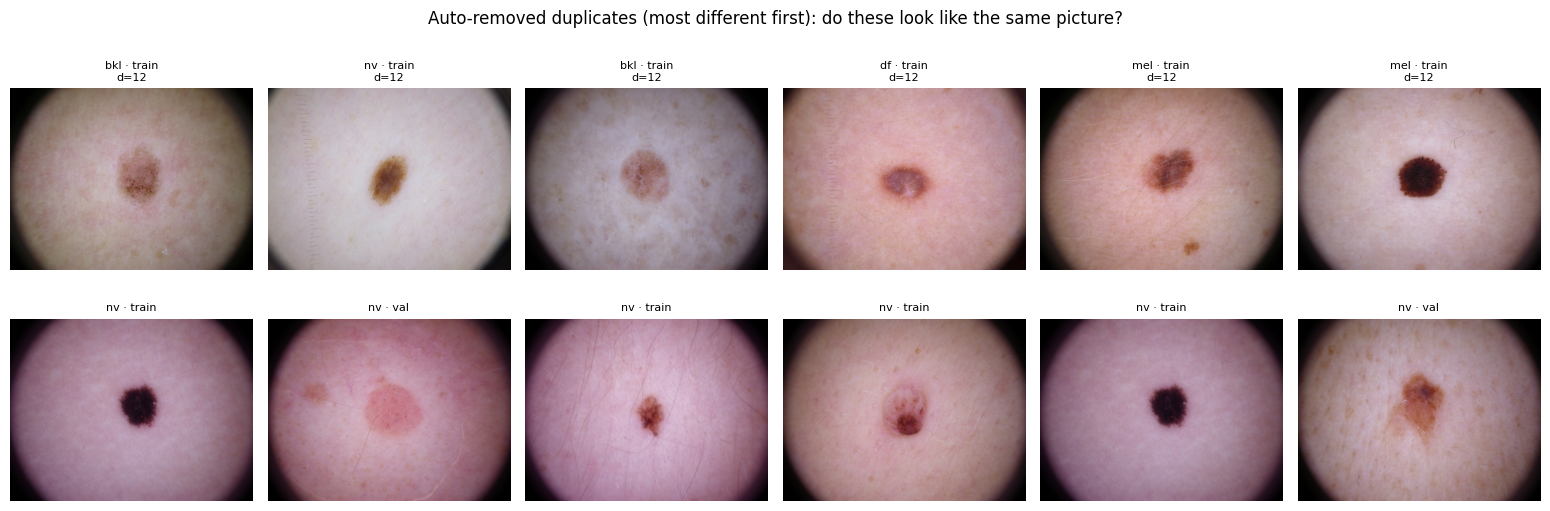

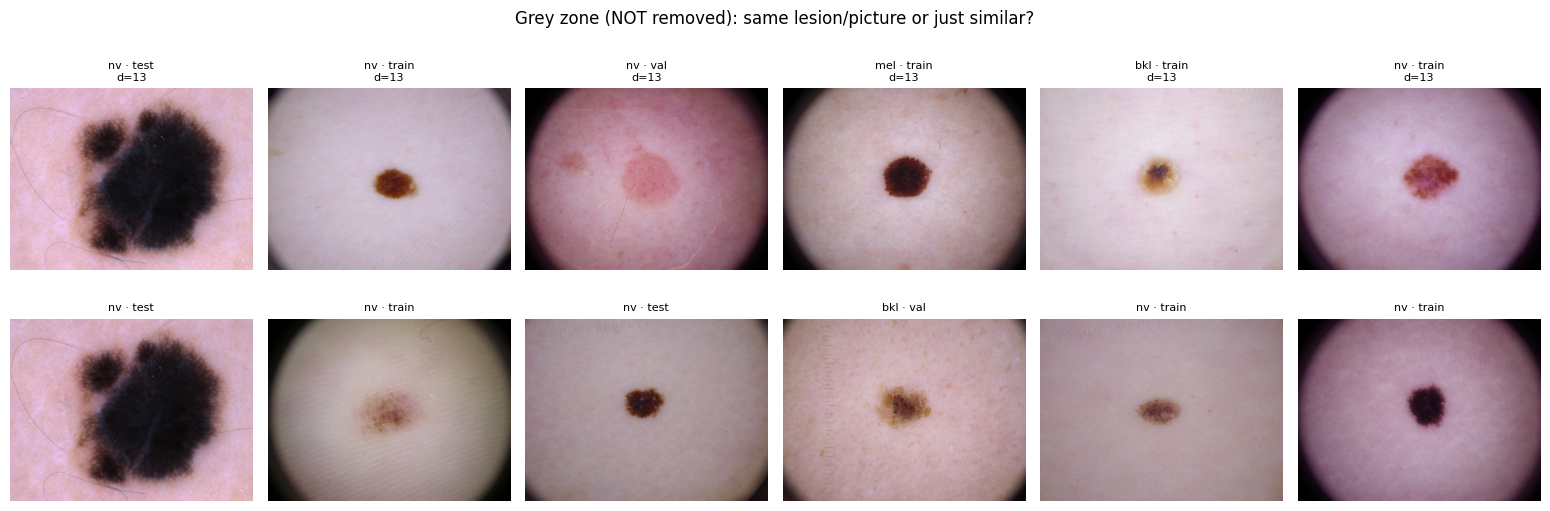

In [8]:
import matplotlib.pyplot as plt

def show_pairs(p, all_df, n, title):
    if len(p) == 0:
        print(f"{title}: none"); return
    p = p.head(n)
    fig, ax = plt.subplots(2, len(p), figsize=(2.6 * len(p), 5.6), squeeze=False)
    for k, r in enumerate(p.itertuples()):
        for row, (col, idc, dxc, spc) in enumerate((("i", "id_i", "dx_i", "split_i"), ("j", "id_j", "dx_j", "split_j"))):
            ax[row, k].imshow(Image.open(all_df.loc[getattr(r, col), "image_path"]).convert("RGB"))
            ax[row, k].set_title(f"{getattr(r, dxc)} · {getattr(r, spc)}" + (f"\nd={r.dist}" if row == 0 else ""), fontsize=8)
            ax[row, k].axis("off")
    fig.suptitle(title); plt.tight_layout(); plt.show()


DEDUP_STATS = {"enabled": bool(DEDUP)}
if DEDUP:
    t0 = time.time()
    all_df = pd.concat([train_df.assign(split="train"), val_df.assign(split="val"), test_df.assign(split="test")], ignore_index=True)
    bits = compute_hashes(all_df, f"{OUT_DIR}/dhash_cache.npz")
    print(f"hashed {len(all_df)} images in {time.time() - t0:.0f}s")
    pairs, drop_ids = plan_dedup(all_df, near_pairs(bits, T_REVIEW), T_DUP)
    os.makedirs(OUT_DIR, exist_ok=True)
    pairs.drop(columns=["i", "j"]).to_csv(f"{OUT_DIR}/near_duplicate_pairs{'_DRYRUN' if DRY_RUN else ''}.csv", index=False)

    summ = (pairs.assign(combo=lambda d: d["split_i"] + "-" + d["split_j"])
                 .groupby(["zone", "combo"]).size().rename("pairs").reset_index())
    print(summ.to_string(index=False) if len(summ) else "No near-duplicate pairs found.")
    dup = pairs[pairs["zone"] == "duplicate"]
    n_diff = int((~dup["same_dx"]).sum())
    vt = int(((dup["split_i"] != "train") & (dup["split_j"] != "train")).sum())
    print(f"duplicate pairs with DIFFERENT labels (label noise, look at them): {n_diff}")
    print(f"duplicate pairs between val/test (reported only, not changed): {vt}")

    before = len(train_df)
    train_df = train_df[~train_df["image_id"].isin(drop_ids)].reset_index(drop=True)
    print(f"train images removed as near-duplicates: {before - len(train_df)}  ({before} -> {len(train_df)})")
    DEDUP_STATS.update(t_dup=T_DUP, t_review=T_REVIEW, duplicate_pairs=int(len(dup)), diff_label_pairs=n_diff,
                       val_test_duplicate_pairs=vt, train_removed=int(before - len(train_df)))
    show_pairs(dup.sort_values("dist", ascending=False), all_df, 6, "Auto-removed duplicates (most different first): do these look like the same picture?")
    show_pairs(pairs[pairs["zone"] == "review"].sort_values("dist"), all_df, 6, "Grey zone (NOT removed): same lesion/picture or just similar?")
else:
    print("DEDUP = False: skipping.")

In [9]:
counts = train_df["label"].value_counts().reindex(range(len(classes))).fillna(0).astype(int).values
assert (counts > 0).all(), "a class has no training images left"

if RESAMPLE:
    targets = compute_targets(counts, TARGET_MODE, CAP_N, FLOOR_N, MAX_REPEAT, MANUAL_TARGETS, classes)
else:
    targets = counts.copy()
class_weights = compute_class_weights(targets, WEIGHT_MODE, EFF_BETA)     # from what the model sees per epoch

# simulate ONE epoch to show exactly what resampling does
if RESAMPLE:
    _idx = build_epoch_indices(train_df["label"].to_numpy(), train_df["lesion_id"].to_numpy(), targets,
                               np.random.default_rng(SEED), LESION_AWARE)
else:
    _idx = np.arange(len(train_df))
table = describe_epoch(_idx, train_df["label"].to_numpy(), train_df["lesion_id"].to_numpy(), classes, counts, targets, class_weights)
print(f"RESAMPLE = {RESAMPLE} | WEIGHT_MODE = {WEIGHT_MODE}  (weights come from per-epoch counts, TRAIN only)")
print(table.to_string(index=False))
print(f"images per epoch: {len(_idx)} (raw train set: {len(train_df)})")
print(f"imbalance ratio (largest/smallest class): raw {counts.max() / counts.min():.1f} -> per epoch {targets.max() / targets.min():.1f}")
print(f"largest/smallest weight ratio: {class_weights.max() / class_weights.min():.1f}")
if RESAMPLE and (targets / counts).max() > 8:
    print("WARNING: some class is repeated more than 8x on average; expect overfitting to those few images.")

RESAMPLE = True | WEIGHT_MODE = inverse  (weights come from per-epoch counts, TRAIN only)
  cls  train_n  per_epoch  pct_of_epoch  unique_imgs  unique_lesions  avg_repeat  weight
akiec      260        500          10.1          260             176        1.92   1.408
  bcc      424        500          10.1          424             268        1.18   1.408
  bkl      855        855          17.3          855             573        1.00   0.823
   df       97        500          10.1           97              63        5.15   1.408
  mel      873        873          17.7          873             481        1.00   0.806
   nv     5333       1200          24.4         1200            1187        1.00   0.587
 vasc      108        500          10.1          108              76        4.63   1.408
images per epoch: 4928 (raw train set: 7950)
imbalance ratio (largest/smallest class): raw 55.0 -> per epoch 2.4
largest/smallest weight ratio: 2.4


## 3 · Data, model, loss

In [10]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from torchvision.models import resnet50, ResNet50_Weights
from PIL import Image
from concurrent.futures import ThreadPoolExecutor

def seed_everything(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
seed_everything(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
USE_AMP = device.type == "cuda"
print("Device:", device, "| mixed precision:", USE_AMP)

MEAN, STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]
if AUG_LEVEL == "strong":
    train_tf = transforms.Compose([
        transforms.RandomResizedCrop(IMG_SIZE, scale=(0.65, 1.0), ratio=(0.85, 1.18)),
        transforms.RandomHorizontalFlip(),
        transforms.RandomVerticalFlip(),
        transforms.RandomRotation(30),
        transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2, hue=0.03),
        transforms.ToTensor(),
        transforms.Normalize(MEAN, STD),
        transforms.RandomErasing(p=0.25, scale=(0.02, 0.10), value=0),
    ])
else:                                                  # same as v3
    train_tf = transforms.Compose([
        transforms.Resize((IMG_SIZE, IMG_SIZE)),
        transforms.RandomHorizontalFlip(),
        transforms.RandomVerticalFlip(),
        transforms.RandomRotation(30),
        transforms.ColorJitter(brightness=0.1, contrast=0.1, saturation=0.1, hue=0.02),
        transforms.ToTensor(),
        transforms.Normalize(MEAN, STD),
    ])
eval_tf = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])


def preload_images(frames, size, workers=8):
    """Decode + resize every needed image once; training then skips JPEG decoding."""
    paths = {}
    for d in frames:
        paths.update(zip(d["image_id"], d["image_path"]))
    ids = list(paths)
    arr = np.empty((len(ids), size, size, 3), dtype=np.uint8)
    def load(k):
        im = Image.open(paths[ids[k]])
        im.draft("RGB", (size, size))
        arr[k] = np.asarray(im.convert("RGB").resize((size, size), Image.BILINEAR))
    with ThreadPoolExecutor(workers) as ex:
        list(ex.map(load, range(len(ids))))
    return {"array": arr, "index": {i: k for k, i in enumerate(ids)}}


STORE = None
if PRELOAD:
    t0 = time.time()
    STORE = preload_images([train_df, val_df, test_df], IMG_SIZE)
    print(f"Preloaded {len(STORE['index'])} images at {IMG_SIZE}px into RAM ({STORE['array'].nbytes / 1e9:.1f} GB) in {time.time() - t0:.0f}s")


class HAM10000Dataset(Dataset):
    def __init__(self, dataframe, transform=None, store=None):
        self.df = dataframe.reset_index(drop=True)
        self.transform, self.store = transform, store
        if store is not None:
            self.rows = np.array([store["index"][i] for i in self.df["image_id"]])
    def __len__(self):
        return len(self.df)
    def __getitem__(self, idx):
        if self.store is not None:
            image = Image.fromarray(self.store["array"][self.rows[idx]])
        else:
            image = Image.open(self.df.iloc[idx]["image_path"]).convert("RGB")
        if self.transform:
            image = self.transform(image)
        return image, int(self.df.iloc[idx]["label"])

def seed_worker(worker_id):
    s = torch.initial_seed() % 2**32
    np.random.seed(s); random.seed(s)

g = torch.Generator(); g.manual_seed(SEED)
kw = dict(batch_size=BATCH_SIZE, num_workers=2, pin_memory=(device.type == "cuda"), worker_init_fn=seed_worker)

class EpochResampler(torch.utils.data.Sampler):
    """Gives DataLoader a fresh class-rebalanced list of row positions every epoch (see build_epoch_indices)."""
    def __init__(self, labels, lesion_ids, targets, seed, lesion_aware=True, every_epoch=True):
        self.labels, self.lesion_ids, self.targets = np.asarray(labels), np.asarray(lesion_ids), np.asarray(targets)
        self.seed, self.lesion_aware, self.every_epoch, self.epoch = seed, lesion_aware, every_epoch, 0
    def __len__(self):
        return int(self.targets.sum())
    def __iter__(self):
        ep = self.epoch if self.every_epoch else 0
        self.epoch += 1
        rng = np.random.default_rng(self.seed * 1000 + ep)
        return iter(build_epoch_indices(self.labels, self.lesion_ids, self.targets, rng, self.lesion_aware).tolist())

train_ds = HAM10000Dataset(train_df, train_tf, STORE)  # train_df was reset_index'd, so row position == dataset index
if RESAMPLE:
    sampler = EpochResampler(train_df["label"].to_numpy(), train_df["lesion_id"].to_numpy(), targets, SEED,
                             LESION_AWARE, RESAMPLE_EACH_EPOCH)
    train_loader = DataLoader(train_ds, sampler=sampler, **kw)
else:
    train_loader = DataLoader(train_ds, shuffle=True, generator=g, **kw)
val_loader  = DataLoader(HAM10000Dataset(val_df, eval_tf, STORE), shuffle=False, **kw)
test_loader = DataLoader(HAM10000Dataset(test_df, eval_tf, STORE), shuffle=False, **kw)
print("Training images seen per epoch:", len(sampler) if RESAMPLE else len(train_ds))
print("Train / val / test batches:", len(train_loader), len(val_loader), len(test_loader))

Device: cuda | mixed precision: True
Preloaded 9974 images at 224px into RAM (1.5 GB) in 54s
Training images seen per epoch: 4928
Train / val / test batches: 154 32 32


In [11]:
def build_model(name, k):
    if name == "resnet50":
        m = resnet50(weights=ResNet50_Weights.DEFAULT)
        m.fc = nn.Linear(m.fc.in_features, k)
    elif name == "efficientnet_b3":
        from torchvision.models import efficientnet_b3, EfficientNet_B3_Weights
        m = efficientnet_b3(weights=EfficientNet_B3_Weights.DEFAULT)
        m.classifier[1] = nn.Linear(m.classifier[1].in_features, k)
    else:
        from torchvision.models import convnext_tiny, ConvNeXt_Tiny_Weights
        m = convnext_tiny(weights=ConvNeXt_Tiny_Weights.DEFAULT)
        m.classifier[2] = nn.Linear(m.classifier[2].in_features, k)
    return m


class EMA:
    """Exponential moving average of ALL weights and batch-norm statistics. The averaged copy is what we evaluate."""
    def __init__(self, model, decay):
        self.decay = decay
        self.shadow = copy.deepcopy(model).eval()
        for p in self.shadow.parameters():
            p.requires_grad_(False)
        self.e, self.m = self.shadow.state_dict(), model.state_dict()     # tensors share storage with the live ones
    @torch.no_grad()
    def update(self, step):
        d = min(self.decay, (1 + step) / (10 + step))                    # warm-up so early averages are not stuck at init
        for k, v in self.e.items():
            if v.dtype.is_floating_point:
                v.mul_(d).add_(self.m[k].detach(), alpha=1 - d)
            else:
                v.copy_(self.m[k])


model = build_model(BACKBONE, len(classes)).to(device)
ema = EMA(model, EMA_DECAY) if USE_EMA else None
eval_net = ema.shadow if USE_EMA else model

weight_tensor = torch.tensor(class_weights, dtype=torch.float32, device=device)
criterion = nn.CrossEntropyLoss(weight=weight_tensor, label_smoothing=LABEL_SMOOTH)    # mode "none" -> all-ones weights
optimizer = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
scaler = torch.amp.GradScaler("cuda", enabled=USE_AMP)

steps_per_epoch = len(train_loader)
total_steps, warm_steps = EPOCHS * steps_per_epoch, WARMUP_EPOCHS * steps_per_epoch
def lr_lambda(step):
    if warm_steps and step < warm_steps:
        return (step + 1) / warm_steps
    prog = (step - warm_steps) / max(1, total_steps - warm_steps)
    return 0.02 + 0.98 * 0.5 * (1 + math.cos(math.pi * min(1.0, prog)))      # decays to 2% of the peak rate
scheduler = torch.optim.lr_scheduler.LambdaLR(optimizer, lr_lambda) if USE_SCHEDULE else None

print(f"Model: {BACKBONE} (ImageNet pretrained) | loss: weighted CE ({WEIGHT_MODE}), label smoothing {LABEL_SMOOTH}")
print(f"Optimizer: AdamW | peak lr {LR} | weight decay {WEIGHT_DECAY} | schedule {USE_SCHEDULE} | EMA {USE_EMA} | steps/epoch {steps_per_epoch}")

Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 164MB/s]


Model: resnet50 (ImageNet pretrained) | loss: weighted CE (inverse), label smoothing 0.1
Optimizer: AdamW | peak lr 0.0002 | weight decay 0.0001 | schedule True | EMA True | steps/epoch 154


## 4 · Training
Each epoch is validated with the (EMA-smoothed, if on) weights. The kept checkpoint is the epoch with the highest **validation macro-F1** (`SELECT = "best"`) or simply the last one (`SELECT = "last"`). The validation loss shown is *unweighted* cross-entropy. The training loss is the loss being optimised (weighted, label-smoothed), so it should not be compared across settings.

In [12]:
from sklearn.metrics import f1_score, balanced_accuracy_score, recall_score, roc_auc_score

K = len(classes)
mel_idx = class_to_idx["mel"]
FLIPS = [lambda x: x, lambda x: x.flip(3), lambda x: x.flip(2), lambda x: x.flip((2, 3))]

@torch.no_grad()
def predict(loader, net, tta=False):
    """Logits for every image. tta=True averages the logits over 4 flips."""
    net.eval()
    logits, ys = [], []
    for x, y in loader:
        x = x.to(device, non_blocking=True)
        outs = []
        for f in (FLIPS if tta else FLIPS[:1]):
            with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=USE_AMP):
                outs.append(net(f(x)).float())
        logits.append(torch.stack(outs).mean(0).cpu()); ys.append(y)
    return torch.cat(logits), torch.cat(ys)


def summarize(logits, y):
    """All the metrics we report, from numpy logits and labels."""
    pred = logits.argmax(1)
    probs = torch.softmax(torch.tensor(logits), 1).numpy()
    try:
        auc = roc_auc_score(y, probs, multi_class="ovr", average="macro", labels=list(range(K)))
    except ValueError:
        auc = float("nan")
    return dict(acc=float((pred == y).mean()), bal=balanced_accuracy_score(y, pred),
                mf1=f1_score(y, pred, average="macro", labels=list(range(K)), zero_division=0),
                recalls=recall_score(y, pred, labels=list(range(K)), average=None, zero_division=0), auc=auc, pred=pred)


def tune_bias(logits, y, mel_floor=None, grid=np.arange(-1.5, 1.51, 0.25), passes=3, min_gain=1e-3):
    """Per-class additive offsets on the logits that maximise macro-F1 (on VALIDATION data), found by coordinate ascent.
    Coarse grid, limited range and a minimum gain per change keep it from fitting validation noise too hard."""
    def score(b):
        pred = (logits + b).argmax(1)
        s = f1_score(y, pred, average="macro", labels=list(range(K)), zero_division=0)
        if mel_floor is not None:
            rec = recall_score(y, pred, labels=[mel_idx], average=None, zero_division=0)[0]
            if rec < mel_floor:
                s -= 10 * (mel_floor - rec)
        return s
    b = np.zeros(K)
    base = best = score(b)
    for _ in range(passes):
        improved = False
        for c in range(K):
            for gv in grid:
                if gv == b[c]:
                    continue
                nb = b.copy(); nb[c] = gv
                s = score(nb)
                if s > best + min_gain:
                    best, b, improved = s, nb, True
        if not improved:
            break
    return b, base, best


history, best_f1, best_epoch, best_state = [], -1.0, 0, None
global_step, t_start = 0, time.time()

for epoch in range(1, EPOCHS + 1):
    t0 = time.time()
    model.train()
    loss_sum, n = 0.0, 0
    for images, labels in train_loader:
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)
        optimizer.zero_grad(set_to_none=True)
        with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=USE_AMP):
            outputs = model(images)
            loss = criterion(outputs, labels)
        scaler.scale(loss).backward()
        scaler.unscale_(optimizer)
        torch.nn.utils.clip_grad_norm_(model.parameters(), GRAD_CLIP)
        scaler.step(optimizer)
        scaler.update()
        if scheduler is not None:
            scheduler.step()
        if ema is not None:
            ema.update(global_step)
        global_step += 1
        loss_sum += loss.item() * labels.size(0)
        n += labels.size(0)
    train_loss = loss_sum / n

    val_logits, val_y = predict(val_loader, eval_net)
    val_loss = F.cross_entropy(val_logits, val_y).item()          # unweighted, comparable across runs
    pred, yv = val_logits.argmax(1).numpy(), val_y.numpy()
    val_f1 = f1_score(yv, pred, average="macro", labels=list(range(K)), zero_division=0)
    val_bal = balanced_accuracy_score(yv, pred)
    val_mel = recall_score(yv, pred, labels=[mel_idx], average=None, zero_division=0)[0]
    history.append(dict(epoch=epoch, lr=optimizer.param_groups[0]["lr"], train_loss=train_loss, val_loss=val_loss,
                        val_acc=float((pred == yv).mean()), val_bal_acc=val_bal, val_macro_f1=val_f1, val_mel_recall=val_mel))

    star = ""
    if SELECT == "last" or val_f1 > best_f1:
        best_f1, best_epoch = val_f1, epoch
        best_state = {k: v.detach().cpu().clone() for k, v in eval_net.state_dict().items()}
        star = "  <- kept" if SELECT == "best" else ""
    print(f"Epoch {epoch:02d}/{EPOCHS} | lr {optimizer.param_groups[0]['lr']:.1e} | train loss {train_loss:.4f} | val loss {val_loss:.4f} | "
          f"val macro-F1 {val_f1:.4f} | val bal-acc {val_bal:.4f} | val mel recall {val_mel:.3f} | {time.time() - t0:.0f}s{star}")

print(f"\nKept epoch: {best_epoch} (val macro-F1 {best_f1:.4f}) | total time {(time.time() - t_start) / 60:.1f} min")
hist_df = pd.DataFrame(history)

Epoch 01/25 | lr 2.0e-04 | train loss 1.5456 | val loss 0.9853 | val macro-F1 0.5147 | val bal-acc 0.6553 | val mel recall 0.573 | 48s  <- kept
Epoch 02/25 | lr 2.0e-04 | train loss 1.0268 | val loss 0.9033 | val macro-F1 0.5762 | val bal-acc 0.6693 | val mel recall 0.669 | 45s  <- kept
Epoch 03/25 | lr 2.0e-04 | train loss 0.9389 | val loss 0.7889 | val macro-F1 0.5879 | val bal-acc 0.6517 | val mel recall 0.710 | 46s  <- kept
Epoch 04/25 | lr 1.9e-04 | train loss 0.8602 | val loss 0.7014 | val macro-F1 0.6315 | val bal-acc 0.6740 | val mel recall 0.734 | 46s  <- kept
Epoch 05/25 | lr 1.9e-04 | train loss 0.8134 | val loss 0.6910 | val macro-F1 0.6360 | val bal-acc 0.6816 | val mel recall 0.806 | 45s  <- kept
Epoch 06/25 | lr 1.8e-04 | train loss 0.7792 | val loss 0.6665 | val macro-F1 0.6587 | val bal-acc 0.6991 | val mel recall 0.823 | 45s  <- kept
Epoch 07/25 | lr 1.7e-04 | train loss 0.7389 | val loss 0.6790 | val macro-F1 0.6526 | val bal-acc 0.6948 | val mel recall 0.790 | 46s
E

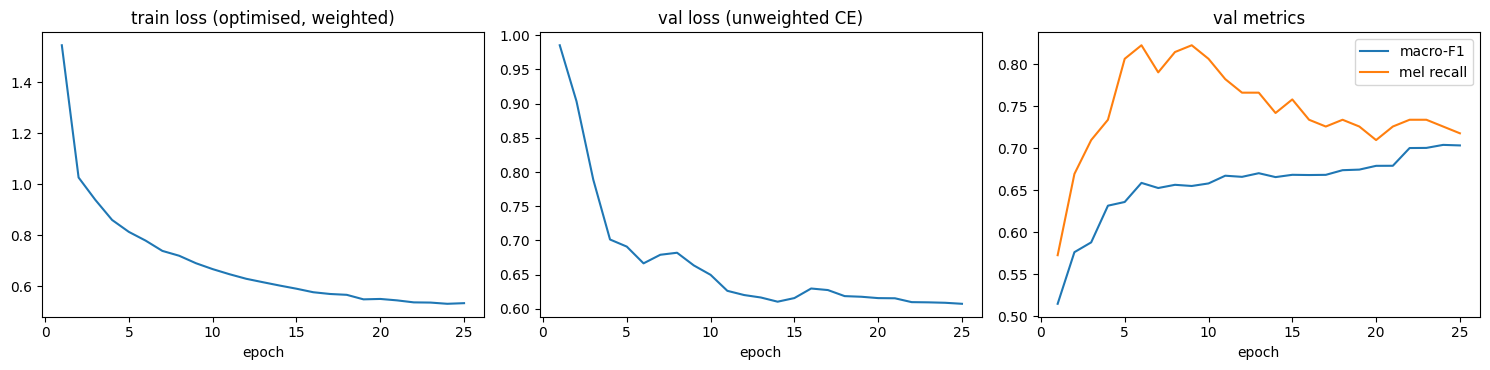

In [13]:
import matplotlib.pyplot as plt
if len(hist_df) > 1:
    fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
    ax[0].plot(hist_df.epoch, hist_df.train_loss); ax[0].set_title("train loss (optimised, weighted)")
    ax[1].plot(hist_df.epoch, hist_df.val_loss); ax[1].set_title("val loss (unweighted CE)")
    ax[2].plot(hist_df.epoch, hist_df.val_macro_f1, label="macro-F1")
    ax[2].plot(hist_df.epoch, hist_df.val_mel_recall, label="mel recall"); ax[2].legend(); ax[2].set_title("val metrics")
    for a in ax: a.set_xlabel("epoch")
    plt.tight_layout(); plt.show()
else:
    print("Only one epoch (dry run): skipping curves.")

## 5 · Test evaluation (test set is used once, with the best-validation checkpoint)

[rs_inverse] kept epoch 24 | TTA True | EMA True
per-class offsets ( akiec, bcc, bkl, df, mel, nv, vasc ): [-0.5  -0.25  0.    1.5  -0.5   1.    1.25]
validation macro-F1 0.6737 -> 0.7396 after tuning (this gain is on the data it was tuned on, so it is optimistic)

          val_F1  TEST_F1  TEST_bal_acc  TEST_acc  TEST_mel_rec  TEST_AUC
     raw  0.6737   0.7902        0.7981    0.8435        0.8036    0.9559
post-hoc  0.7396   0.7726        0.7943    0.8583        0.6429    0.9682

FINAL (what is saved as the result): post-hoc

              precision    recall  f1-score   support

       akiec     0.9231    0.5854    0.7164        41
         bcc     0.7500    0.7778    0.7636        54
         bkl     0.7632    0.7909    0.7768       110
          df     0.5625    0.9000    0.6923        10
         mel     0.6667    0.6429    0.6545       112
          nv     0.9189    0.9257    0.9223       673
        vasc     0.8333    0.9375    0.8824        16

    accuracy                  

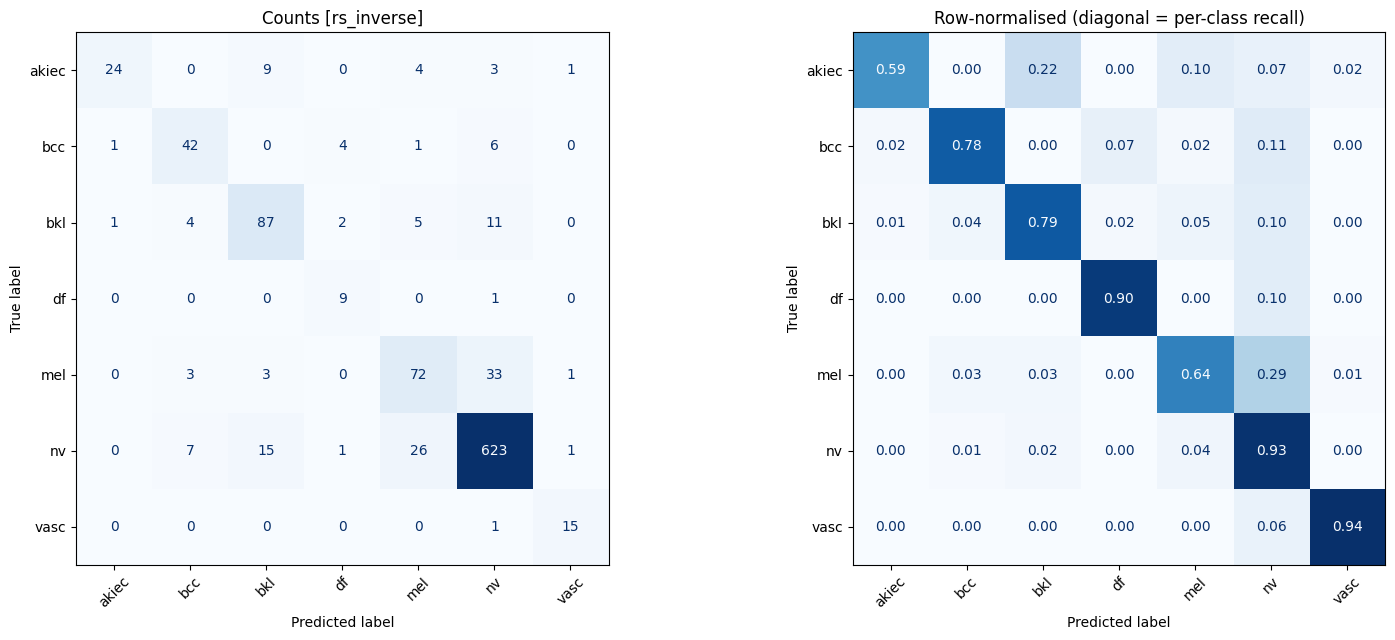

In [14]:
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

eval_net.load_state_dict(best_state)
val_logits, val_y = predict(val_loader, eval_net, tta=USE_TTA)
test_logits, test_y = predict(test_loader, eval_net, tta=USE_TTA)
VL, TL, vy, ty = val_logits.numpy(), test_logits.numpy(), val_y.numpy(), test_y.numpy()

bias, v_before, v_after = np.zeros(K), None, None
if POSTHOC:
    bias, v_before, v_after = tune_bias(VL, vy, MEL_RECALL_FLOOR)
raw_v, raw_t = summarize(VL, vy), summarize(TL, ty)
adj_v, adj_t = summarize(VL + bias, vy), summarize(TL + bias, ty)
final_t, final_logits = (adj_t, TL + bias) if POSTHOC else (raw_t, TL)

print(f"[{RUN_LABEL}] kept epoch {best_epoch} | TTA {USE_TTA} | EMA {USE_EMA}")
if POSTHOC:
    print("per-class offsets (", ", ".join(classes), "):", np.round(bias, 2))
    print(f"validation macro-F1 {v_before:.4f} -> {v_after:.4f} after tuning (this gain is on the data it was tuned on, so it is optimistic)\n")
tab = pd.DataFrame({
    "": ["raw", "post-hoc"] if POSTHOC else ["raw"],
    "val_F1": [raw_v["mf1"], adj_v["mf1"]][:2 if POSTHOC else 1],
    "TEST_F1": [raw_t["mf1"], adj_t["mf1"]][:2 if POSTHOC else 1],
    "TEST_bal_acc": [raw_t["bal"], adj_t["bal"]][:2 if POSTHOC else 1],
    "TEST_acc": [raw_t["acc"], adj_t["acc"]][:2 if POSTHOC else 1],
    "TEST_mel_rec": [raw_t["recalls"][mel_idx], adj_t["recalls"][mel_idx]][:2 if POSTHOC else 1],
    "TEST_AUC": [raw_t["auc"], adj_t["auc"]][:2 if POSTHOC else 1]})
print(tab.round(4).to_string(index=False))
print(f"\nFINAL (what is saved as the result): {'post-hoc' if POSTHOC else 'raw'}\n")
print(classification_report(ty, final_t["pred"], labels=list(range(K)), target_names=classes, digits=4, zero_division=0))

fig, ax = plt.subplots(1, 2, figsize=(16, 6.5))
cm = confusion_matrix(ty, final_t["pred"], labels=list(range(K)))
ConfusionMatrixDisplay(cm, display_labels=classes).plot(ax=ax[0], cmap="Blues", xticks_rotation=45, values_format="d", colorbar=False)
ax[0].set_title(f"Counts [{RUN_LABEL}]")
cmn = confusion_matrix(ty, final_t["pred"], labels=list(range(K)), normalize="true")
ConfusionMatrixDisplay(cmn, display_labels=classes).plot(ax=ax[1], cmap="Blues", xticks_rotation=45, values_format=".2f", colorbar=False)
ax[1].set_title("Row-normalised (diagonal = per-class recall)")
plt.tight_layout(); plt.show()

y_true, y_pred = ty, final_t["pred"]
acc, bal, mf1, auc, recalls = final_t["acc"], final_t["bal"], final_t["mf1"], final_t["auc"], final_t["recalls"]

In [15]:
os.makedirs(OUT_DIR, exist_ok=True)
feats = "-".join(n for n, on in (("sch", USE_SCHEDULE), ("ema", USE_EMA), ("tta", USE_TTA), ("ph", POSTHOC)) if on)
tag = (f"v4_{BACKBONE}{IMG_SIZE}_{RUN_LABEL}"
       + (f"_{TARGET_MODE}" + (f"_cap{CAP_N}_floor{FLOOR_N}" if TARGET_MODE == "auto" else "") if RESAMPLE else "")
       + f"_{AUG_LEVEL}_ls{LABEL_SMOOTH}_{feats or 'plain'}_ep{EPOCHS}_{SELECT}"
       + f"_seed{SEED}" + ("_DRYRUN" if DRY_RUN else ""))

def block(s, with_cm=False):
    d = {"accuracy": float(s["acc"]), "balanced_accuracy": float(s["bal"]), "macro_f1": float(s["mf1"]),
         "macro_auc": float(s["auc"]), "recall": dict(zip(classes, [float(r) for r in s["recalls"]]))}
    if with_cm:
        d["confusion"] = confusion_matrix(ty, s["pred"], labels=list(range(K))).tolist()
    return d

results = {
    "tag": tag, "version": "v4", "weight_mode": WEIGHT_MODE, "seed": SEED, "dry_run": DRY_RUN, "best_epoch": int(best_epoch),
    "config": dict(backbone=BACKBONE, epochs=EPOCHS, batch_size=BATCH_SIZE, lr=LR, weight_decay=WEIGHT_DECAY, img_size=IMG_SIZE,
                   eff_beta=EFF_BETA, split_dir=SPLIT_DIR, schedule=USE_SCHEDULE, warmup_epochs=WARMUP_EPOCHS, ema=USE_EMA,
                   ema_decay=EMA_DECAY, label_smoothing=LABEL_SMOOTH, aug=AUG_LEVEL, grad_clip=GRAD_CLIP, select=SELECT,
                   tta=USE_TTA, posthoc=POSTHOC, mel_recall_floor=MEL_RECALL_FLOOR),
    "class_weights": dict(zip(classes, [float(w) for w in class_weights])),
    "train_counts": dict(zip(classes, [int(c) for c in counts])),
    "per_epoch_targets": dict(zip(classes, [int(t) for t in targets])),
    "resample": dict(on=bool(RESAMPLE), mode=TARGET_MODE, cap=CAP_N, floor=FLOOR_N, max_repeat=MAX_REPEAT,
                     every_epoch=bool(RESAMPLE_EACH_EPOCH), lesion_aware=bool(LESION_AWARE)),
    "dedup": DEDUP_STATS,
    "test": block(final_t, True),                 # what the run is judged on (post-hoc if POSTHOC, else raw)
    "test_raw": block(raw_t),                     # same model, no post-hoc offsets
    "posthoc": {"on": bool(POSTHOC), "bias": dict(zip(classes, [float(b) for b in bias])),
                "val_f1_before": v_before, "val_f1_after": v_after},
    "best_val_macro_f1": float(best_f1),
    "history": history,
    "env": {"torch": torch.__version__, "gpu": torch.cuda.get_device_name(0) if torch.cuda.is_available() else "cpu"},
}
with open(f"{OUT_DIR}/results_{tag}.json", "w") as f:
    json.dump(results, f, indent=2)
softmax = lambda z: torch.softmax(torch.tensor(z), 1).numpy()
np.savez(f"{OUT_DIR}/probs_{tag}.npz", val_probs=softmax(VL), val_y=vy, test_probs=softmax(TL), test_y=ty)   # raw (no offsets)
if not DRY_RUN:
    torch.save({"model_state_dict": best_state, "class_to_idx": class_to_idx, "best_epoch": best_epoch, "backbone": BACKBONE,
                "img_size": IMG_SIZE, "bias": bias}, f"{OUT_DIR}/best_{tag}.pth")
print("Saved results (and probabilities) to", OUT_DIR, "| tag:", tag)

Saved results (and probabilities) to /content/drive/MyDrive/HAM10000_model/imbalance_runs | tag: v4_resnet50224_rs_inverse_auto_cap1200_floor500_strong_ls0.1_sch-ema-tta-ph_ep25_best_seed42


## 6 · Compare everything saved so far
Reads saved files only (no training). `raw_f1` is the same model without post-hoc offsets (v4 runs only). Rows from earlier notebooks stay for reference; they used different protocols.
The second table is **mean ± std over seeds** for runs that differ only in `SEED`. That is the number to quote. With ~10 test images for `df` and 16 for `vasc`, one image moves those recalls by 10 and 6 points, so don't read much into single runs.

In [16]:
rows = [{"run": "ORIGINAL baseline (no aug, val-loss select)", "acc": 0.8307, "bal_acc": 0.6504, "macro_f1": 0.6542,
         "auc": 0.9609, "mel_rec": 0.5625, "df_rec": 0.2000, "akiec_rec": 0.5122, "best_ep": 2, "raw_f1": np.nan}]
for f in sorted(glob.glob(f"{OUT_DIR}/results_*.json")):
    r = json.load(open(f))
    if r.get("dry_run"):
        continue
    t, raw = r["test"], r.get("test_raw")
    rows.append({"run": r["tag"], "acc": t["accuracy"], "bal_acc": t["balanced_accuracy"], "macro_f1": t["macro_f1"],
                 "auc": t["macro_auc"], "mel_rec": t["recall"]["mel"], "df_rec": t["recall"]["df"],
                 "akiec_rec": t["recall"]["akiec"], "best_ep": r["best_epoch"], "raw_f1": raw["macro_f1"] if raw else np.nan})
cmp_df = pd.DataFrame(rows)
pd.set_option("display.width", 250, "display.max_colwidth", 90)
print(cmp_df.round(4).to_string(index=False))

seeded = cmp_df[cmp_df["run"].str.contains(r"_seed\d+$")].copy()
seeded["config"] = seeded["run"].str.replace(r"_seed\d+$", "", regex=True)
agg = seeded.groupby("config").agg(n=("run", "count"), f1_mean=("macro_f1", "mean"), f1_std=("macro_f1", "std"),
                                   bal_mean=("bal_acc", "mean"), bal_std=("bal_acc", "std"),
                                   mel_mean=("mel_rec", "mean"), auc_mean=("auc", "mean"))
print("\nMean +- std over seeds (configs with 2+ seeds):")
print(agg[agg["n"] >= 2].round(4).to_string() if (agg["n"] >= 2).any() else "  (run the same config with 2+ different SEED values first)")

                                                                                         run    acc  bal_acc  macro_f1    auc  mel_rec  df_rec  akiec_rec  best_ep  raw_f1
                                                 ORIGINAL baseline (no aug, val-loss select) 0.8307   0.6504    0.6542 0.9609   0.5625     0.2     0.5122        2     NaN
                                                                              inverse_seed42 0.7992   0.7994    0.6775 0.9671   0.7054     0.9     0.7317       11     NaN
                                                     rs_inverse_auto_cap1200_floor500_seed42 0.8061   0.7731    0.7447 0.9656   0.7232     0.8     0.6098       12     NaN
v4_resnet50224_rs_inverse_auto_cap1200_floor500_strong_ls0.1_sch-ema-tta-ph_ep25_best_seed42 0.8583   0.7943    0.7726 0.9682   0.6429     0.9     0.5854       24  0.7902
v4_resnet50224_rs_inverse_auto_cap1200_floor500_strong_ls0.1_sch-ema-tta-ph_ep25_best_seed43 0.8317   0.7344    0.7515 0.9748   0.7232     0.6   

## 7 · Seed ensemble
Averages the saved probabilities of runs that differ only in `SEED` (v4 runs, 2+ seeds), then tunes the post-hoc offsets on the **averaged validation** probabilities and applies them to the averaged test probabilities. Ensembling several seeds usually gives a small but reliable gain, and it is the most dependable way to reduce single-run luck. Needs a session where the notebook has been run (it uses `tune_bias` from section 4).

In [17]:
from collections import defaultdict
groups = defaultdict(list)
for f in sorted(glob.glob(f"{OUT_DIR}/probs_v4_*.npz")):
    tg = os.path.basename(f)[len("probs_"):-len(".npz")]
    if "DRYRUN" not in tg:
        groups[re.sub(r"_seed\d+$", "", tg)].append(f)

out = []
for cfg, files in groups.items():
    if len(files) < 2:
        continue
    zs = [np.load(f) for f in files]
    assert all((z["test_y"] == zs[0]["test_y"]).all() and (z["val_y"] == zs[0]["val_y"]).all() for z in zs), "different splits!"
    vp, tp = np.mean([z["val_probs"] for z in zs], 0), np.mean([z["test_probs"] for z in zs], 0)
    vy_, ty_ = zs[0]["val_y"], zs[0]["test_y"]
    VLe, TLe = np.log(vp + 1e-9), np.log(tp + 1e-9)
    b_, _, _ = tune_bias(VLe, vy_, MEL_RECALL_FLOOR)
    for name, lg in (("ensemble raw", TLe), ("ensemble + post-hoc", TLe + b_)):
        s = summarize(lg, ty_)
        out.append({"config": cfg[:70], "n_seeds": len(files), "variant": name, "macro_f1": s["mf1"], "bal_acc": s["bal"],
                    "mel_rec": s["recalls"][mel_idx], "auc": s["auc"]})
print(pd.DataFrame(out).round(4).to_string(index=False) if out else "Need 2+ non-dry v4 runs of the same config with different SEEDs.")

                                                                config  n_seeds             variant  macro_f1  bal_acc  mel_rec    auc
v4_resnet50224_rs_inverse_auto_cap1200_floor500_strong_ls0.1_sch-ema-t        4        ensemble raw    0.7815   0.8173   0.8571 0.9727
v4_resnet50224_rs_inverse_auto_cap1200_floor500_strong_ls0.1_sch-ema-t        4 ensemble + post-hoc    0.7773   0.7547   0.6875 0.9791
